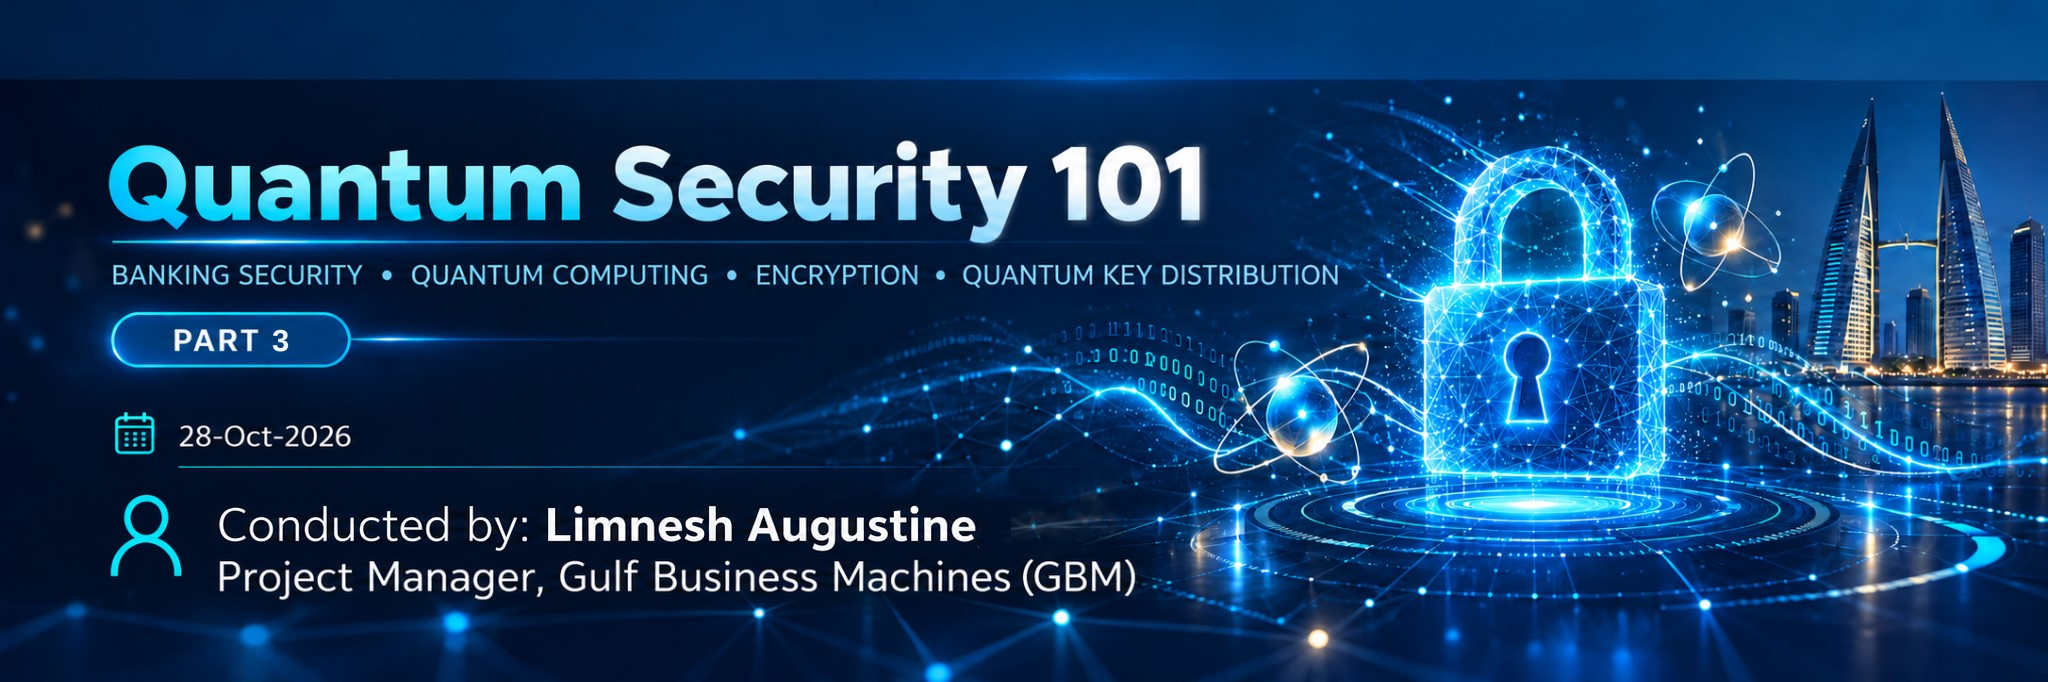
# PART 3 · From a Laser Pointer to Quantum Keys
**BITEX 2026  /  BAHRAIN SAMPLE BANK (BSB)**

*Photons, a beam splitter, weak pulses, and how Alice and Bob notice Eve.*

> **Your mission:** Use the same BSB story to explore a completely different way of establishing secret encryption keys.

**🔵 LIVE** = follow along in the workshop &nbsp;&nbsp; **🟠 OPTIONAL** = explore afterward  

**How to use:** Read the short explanation, **predict what will happen**, then run the code. Change only values marked **✏️ YOUR TURN**. You do not need to understand every helper function to do the experiments.

---


In [5]:
# @title ⚙️ Workshop setup — run once
# Install Qiskit (if it isn't installed yet)
!pip install qiskit -q
!pip install pylatexenc -q
import sys, subprocess, importlib.util, math, io, base64, hashlib, html
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

for package, spec in [('ipywidgets','ipywidgets>=7.7'),('qiskit','qiskit>=0.45.1'),('sklearn','scikit-learn>=1.2')]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable,'-m','pip','-q','install',spec])
import ipywidgets as widgets
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

RNG = np.random.default_rng(20261028)
HPLANCK, CLIGHT, WL_NM = 6.62607015e-34, 299792458., 650.
PULSE_RATE_DEFAULT = 10_000_000

# Common formatter: not scientific notation unless numbers are very small

def fmt_ph(n):
    n=float(n)
    for threshold,word in [(1e15,'QUADRILLION'),(1e12,'TRILLION'),(1e9,'BILLION'),(1e6,'MILLION'),(1e3,'THOUSAND')]:
        if abs(n)>=threshold: return f'{n/threshold:,.2f} {word}'
    if 0<abs(n)<.01: return f'{n:.3g}'
    return f'{n:,.2f}' if abs(n)<10 else f'{n:,.0f}'

def photon_count(mw,seconds,wavelength_nm=WL_NM):
    return (mw*1e-3*seconds)/(HPLANCK*CLIGHT/(wavelength_nm*1e-9))

def dur(s):
    return f'{s:g} s' if s>=.001 else f'{s*1e6:.3f} µs'

def card(label,value,note='',color='#93c5fd'):
    return (f'<div style="flex:1 1 175px;min-width:0;background:#19375a;padding:15px;border-radius:11px;border:1px solid #3c5a77;box-sizing:border-box">'
        f'<div style="font-size:13px;color:#bfdbfe">{html.escape(str(label))}</div>'
        f'<div style="font-size:25px;font-weight:800;color:{color};margin:8px 0;overflow-wrap:anywhere">{html.escape(str(value))}</div>'
        f'<div style="font-size:12px;color:#cbd5e1">{html.escape(str(note))}</div></div>')

def panel(title, content, foot='', color='#93c5fd'):
    return (f'<div style="background:#0e2441;color:white;border:1px solid #27486e;max-width:1250px;padding:20px;border-radius:15px;box-sizing:border-box;font:14px Arial,sans-serif;line-height:1.5">'
        f'<div style="font-size:22px;font-weight:800;color:{color};margin-bottom:13px">{html.escape(str(title))}</div>'
        f'{content}<div style="font-size:12px;color:#cbd5e1;margin-top:14px">{foot}</div></div>')

def rowcards(*items): return '<div style="display:flex;flex-flow:row wrap;gap:12px">'+''.join(items)+'</div>'

def stat_bar(label,p, color='#60a5fa'):
    w=max(0,min(100,100*float(p)))
    return f'<div style="display:flex;gap:9px;align-items:center;margin:8px 0"><span style="width:90px;color:#dbeafe">{html.escape(str(label))}</span><span style="flex:1;background:#344862;border-radius:8px;overflow:hidden;height:13px"><span style="display:block;width:{w:.4f}%;background:{color};height:100%"></span></span><b style="width:65px;text-align:right">{w:.1f}%</b></div>'

def fig_to_img(fig, dpi=110):
    out=io.BytesIO()
    fig.savefig(out,format='png',dpi=dpi,bbox_inches='tight',facecolor='white',pad_inches=.04)
    plt.close(fig)
    return base64.b64encode(out.getvalue()).decode('ascii')

def bloch_img(state):
    return fig_to_img(plot_bloch_multivector(state, figsize=(2.2,2.2),title=''))

def bits_array(s,n=16):
    t=''.join(str(s).split())
    if len(t)!=n or set(t)-{'0','1'}:
        raise ValueError(f'Enter exactly {n} binary digits (0/1); spaces are allowed.')
    return np.array([int(v) for v in t],dtype=np.uint8)

def bits_string(arr):return ''.join(map(str,np.asarray(arr,dtype=int)))

def bit_tiles(bits,highlights=(),color='#60a5fa'):
    highlights=set(map(int,highlights))
    return '<div style="display:flex;flex-flow:row wrap;gap:5px;align-items:center">'+''.join(
        f'<div style="text-align:center;min-width:33px;border-radius:7px;padding:6px 3px;background:{"#71353f" if i in highlights else "#25466b"};border:1px solid {"#fb7185" if i in highlights else "#446787"}">'
        f'<div style="font-size:10px;color:#cbd5e1">{i+1}</div><b style="color:{"#fda4af" if i in highlights else color};font-size:19px">{int(v)}</b></div>'
        for i,v in enumerate(bits))+'</div>'

def entropy2(p):
    p=np.clip(np.asarray(p,dtype=float),1e-14,1-1e-14)
    return -p*np.log2(p)-(1-p)*np.log2(1-p)

def honest_gain(mu,eta,dark=1e-6): return 1-(1-dark)*np.exp(-eta*np.asarray(mu))

def bb84_rate(mu=.5,nu=.15,eta=.01,err=.015,dark=1e-6,clock=1e7,fec=1.16,q=.5):
    """Asymptotic vacuum+weak-decoy BB84 lower-bound proxy; not finite-key proof.
    Ma et al., PRA 72, 012326 (2005). Vacuum yield Y0 modeled as dark.
    """
    mu=float(mu);nu=float(nu); eta=np.asarray(eta,dtype=float)
    gain_s=honest_gain(mu,eta,dark);gain_d=honest_gain(nu,eta,dark)
    # Misalignment causes errors on signal-generated clicks; dark clicks random
    err_sig=np.clip((err*(gain_s-dark)+.5*dark)/np.maximum(gain_s,1e-20),0,.5)
    err_dec=np.clip((err*(gain_d-dark)+.5*dark)/np.maximum(gain_d,1e-20),0,.5)
    y1=np.maximum(0, mu/(mu*nu-nu*nu)*(gain_d*np.exp(nu)
       -(nu*nu/(mu*mu))*gain_s*np.exp(mu)-((mu*mu-nu*nu)/(mu*mu))*dark))
    q1=mu*np.exp(-mu)*y1
    e1=np.where(y1>1e-16,np.clip((err_dec*gain_d*np.exp(nu)-.5*dark)/(nu*np.maximum(y1,1e-20)),0,.5),.5)
    fraction=q*(q1*(1-entropy2(e1))-fec*gain_s*entropy2(err_sig))
    result=np.maximum(0,clock*fraction)
    if np.ndim(result)==0: result=float(result)
    return result, dict(gain=gain_s,q1=q1,qber=err_sig,e1=e1,y1=y1)

print('Ready — Qiskit, scikit-learn, interactive widgets and BB84 helpers loaded.')


Ready — Qiskit, scikit-learn, interactive widgets and BB84 helpers loaded.


---
## 🔵 LIVE — Step 1 · Follow one pulse: transmitter → medium → receiver

**Imagine switching on a 650 nm laser.** Change its optical power and the pulse duration to see how many photons are emitted in **one pulse**. Then choose a transmitter attenuator, a transmission medium, and Bob's collection and detector efficiency.

Start with **1 mW, 1 second**. Slide the duration down towards **1 µs**, then try increasing attenuation. Every number is an **average photon count**, not a guaranteed individual photon or detector click. The fiber and free-space losses here are deliberately simplified presets, especially at 650 nm.

**Prediction:** A 1 µs pulse from a milliwatt laser still carries an enormous number of photons. How much attenuation would reduce it to nearly one photon?

In [2]:
# 🔵 LIVE — Step 1 · Optical transmitter → medium → receiver
laser_power=widgets.FloatSlider(value=1.,min=.1,max=5.,step=.1,description='Laser (mW)',continuous_update=False,style={'description_width':'100px'},layout=widgets.Layout(width='98%'))
pulse_time=widgets.FloatLogSlider(value=1.,base=10,min=-6,max=0,step=.25,description='Pulse width',readout_format='.3g',continuous_update=False,style={'description_width':'100px'},layout=widgets.Layout(width='98%'))
transmitter_filter=widgets.RadioButtons(options=[('None · 0 dB',0),('ND 10× · 10 dB',10),('ND 100× · 20 dB',20),('ND 1000× · 30 dB',30),('OD 4 · 40 dB',40),('OD 6 · 60 dB',60),('OD 8 · 80 dB',80),('OD 10 · 100 dB',100)],value=30)
medium_loss=widgets.RadioButtons(options=[('No attenuation',0),('Fiber 1 km · 3 dB (teaching)',3),('Fiber 10 km · 30 dB (teaching)',30),('Free space · 10% transmission',10),('Free space · 0.1% transmission',30),('Free space · 0.01% transmission',40)],value=40)
receiver_collection=widgets.RadioButtons(options=[('100%',1.),('50%',.5),('10%',.1),('1%',.01)],value=.1)
receiver_eff=widgets.RadioButtons(options=[('100%',1.),('60%',.6),('25%',.25)],value=1.)
optic_output=widgets.HTML(layout=widgets.Layout(width='100%'))

def stage(label,caption,heading,number,extra,bg,border,fg):
    return f'<div style="flex:1 1 270px;min-width:0;box-sizing:border-box;background:{bg};border:2px solid {border};border-radius:13px;padding:18px;color:#17324f"><div style="font-size:21px;font-weight:900;color:{fg}">{label}</div><div style="font-size:13px;margin:6px 0 18px;color:#475569">{caption}</div><div style="font-size:14px;color:#475569">{heading}</div><div style="font-size:27px;overflow-wrap:anywhere;font-weight:900;color:{fg};margin:6px 0">{number}</div><div style="font-weight:700;color:#334155">photons / one pulse</div><div style="font-size:13px;line-height:1.7;margin-top:15px;color:#334155">{extra}</div></div>'

def update_optical(change=None):
    global photons,photons_per_us,bob_receives,laser_mW,wavelength_nm,seconds,qkd_total_eta
    laser_mW,wavelength_nm,seconds=laser_power.value,WL_NM,pulse_time.value
    photons=photon_count(laser_mW,seconds)
    photons_per_us=photon_count(laser_mW,1e-6)
    after_tx=photons*10**(-transmitter_filter.value/10)
    after_med=after_tx*10**(-medium_loss.value/10)
    qkd_total_eta=10**(-(transmitter_filter.value+medium_loss.value)/10)*receiver_collection.value*receiver_eff.value
    bob_receives=after_med*receiver_collection.value*receiver_eff.value
    content=''.join([
        stage('TRANSMITTER','650 nm laser + pulse + ND filter','Laser emits',fmt_ph(photons),f'Power: {laser_MWstr()}<br>Duration: {dur(seconds)}<br>After ND filter: <b>{fmt_ph(after_tx)}</b> photons<br>Loss: {transmitter_filter.value} dB','#dbeafe','#60a5fa','#1d4ed8'),
        stage('MEDIUM','Fiber or free-space loss preset','Exits the medium',fmt_ph(after_med),f'{html.escape(medium_loss.label if hasattr(medium_loss,"label") else str(medium_loss.value)+" dB")}<br>Medium loss: {medium_loss.value} dB','#ede9fe','#a78bfa','#6d28d9'),
        stage('RECEIVER','Collection and detector efficiency','Mean detected',fmt_ph(bob_receives),f'Collection: {receiver_collection.value:.0%}<br>Detector QE: {receiver_eff.value:.0%}<br>Total transmission: {qkd_total_eta:.3g}','#dcfce7','#4ade80','#15803d')
    ])
    optic_output.value='<div style="display:flex;flex-flow:row wrap;gap:12px">'+content+'</div><div style="background:#0e2441;color:#cbd5e1;padding:12px;border-radius:10px;margin-top:10px;font:13px Arial">Photon counts are expected values. A real single-photon detector produces stochastic clicks; this display does not guarantee a fractional photon is detected.</div>'

def laser_MWstr():return f'{laser_power.value:.1f} mW'

def control_stage(title,color,body):
    return widgets.VBox([widgets.HTML(f'<div style="background:{color};padding:10px 13px;border-radius:9px;color:white;font-weight:900;font-size:16px">{title}</div>')]+body,layout=widgets.Layout(flex='1 1 280px',min_width='255px',padding='8px',border=f'2px solid {color}',margin='2px'))
optic_controls=widgets.HBox([
    control_stage('TRANSMITTER','#2563eb',[laser_power,pulse_time,widgets.HTML('<b>Optical attenuator</b>'),transmitter_filter]),
    control_stage('MEDIUM','#7c3aed',[medium_loss]),
    control_stage('RECEIVER','#16a34a',[widgets.HTML('<b>Collected light</b>'),receiver_collection,widgets.HTML('<b>Detector efficiency (QE)</b>'),receiver_eff])],layout=widgets.Layout(width='100%',flex_flow='row wrap',gap='10px',align_items='flex-start'))
for ctl in (laser_power,pulse_time,transmitter_filter,medium_loss,receiver_collection,receiver_eff):ctl.observe(update_optical,names='value')
update_optical();display(optic_controls,optic_output)

HTML(value='<div style="display:flex;flex-flow:row wrap;gap:12px"><div style="flex:1 1 270px;min-width:0;box-s…

---
## 🔵 LIVE — Step 2 · BB84: Alice prepares, Bob measures

Alice chooses a bit **0 or 1** and an encoding basis: **Z** (states $|0\rangle, |1\rangle$) or **X** (states $|+\rangle, |-\rangle$). Bob chooses his measurement basis independently.

**Try:** Set Alice's basis to Z and bit to 0. Measure using Bob's Z basis, then switch Bob to X. With **matching bases**, the ideal result agrees with Alice's bit; with **unmatched bases**, the two outcomes are **50% / 50%**. The colored status reports a **basis match**, not whether Bob happened to guess the same bit.

**🎯 Explore:** Use *Randomize Alice*, *Randomize Bob*, then **MEASURE**. The Bloch sphere at the right is the **mathematical post-measurement state**; a real BB84 single photon is normally absorbed by the detector, so that picture does not imply an intact photon remains available to copy.

In [6]:

# 🔵 LIVE — Step 2 · Alice → Bob → Qiskit circuit → measurement
# Uses existing notebook helpers:
# bloch_img(), stat_bar(), panel(), control_stage(), RNG

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from IPython.display import display, clear_output
import ipywidgets as widgets

# ----------------------------------------------------
# BB84 STATES
# ----------------------------------------------------

BB84 = {
    ('Z', 0): Statevector([1, 0]),
    ('Z', 1): Statevector([0, 1]),
    ('X', 0): Statevector(np.array([1, 1]) / np.sqrt(2)),
    ('X', 1): Statevector(np.array([1, -1]) / np.sqrt(2))
}

BB84_NAME = {
    ('Z', 0): '|0⟩',
    ('Z', 1): '|1⟩',
    ('X', 0): '|+⟩',
    ('X', 1): '|−⟩'
}

# ----------------------------------------------------
# INTERACTIVE CONTROLS
# ----------------------------------------------------

alice_basis = widgets.ToggleButtons(
    options=[('Z · 0/1', 'Z'), ('X · +/−', 'X')],
    value='Z',
    description='Basis',
    style={'description_width': '55px'}
)

alice_bit = widgets.ToggleButtons(
    options=[('Bit 0', 0), ('Bit 1', 1)],
    value=0,
    description='Bit',
    style={'description_width': '55px'}
)

bob_basis = widgets.ToggleButtons(
    options=[('Z · 0/1', 'Z'), ('X · +/−', 'X')],
    value='Z',
    description='Basis',
    style={'description_width': '55px'}
)

randomize_alice_button = widgets.Button(
    description='🎲 Randomize Alice',
    button_style='info',
    layout=widgets.Layout(width='178px')
)

randomize_bob_button = widgets.Button(
    description='🎲 Randomize Bob',
    button_style='info',
    layout=widgets.Layout(width='178px')
)

measure_button = widgets.Button(
    description='📏 MEASURE',
    button_style='success',
    layout=widgets.Layout(width='180px', height='44px')
)

bb84_output = widgets.HTML(
    layout=widgets.Layout(width='100%')
)

# Native Qiskit circuit output — separate from HTML
bb84_circuit_output = widgets.Output(
    layout=widgets.Layout(
        width='100%',
        border='1px solid #334155',
        padding='12px'
    )
)

bb84_current = {
    'result': None,
    'post': None
}

# ----------------------------------------------------
# BUILD THE REAL QISKIT CIRCUIT
# ----------------------------------------------------

def make_bb84_circuit():

    q = QuantumRegister(1, 'photon')
    c = ClassicalRegister(1, 'bob_bit')

    qc = QuantumCircuit(q, c)

    # ALICE: prepare initial |0⟩
    qc.reset(q[0])

    # Alice encodes bit 0 or bit 1
    if alice_bit.value == 1:
        qc.x(q[0])

    # Alice selects Z or X encoding basis
    if alice_basis.value == 'X':
        qc.h(q[0])

    # Transmission boundary — not an actual gate
    qc.barrier(q[0], label='CHANNEL')

    # BOB: choose measurement basis
    if bob_basis.value == 'X':
        qc.h(q[0])
    else:
        qc.id(q[0])  # Identity: Z basis needs no rotation

    # Bob measures and stores the classical bit
    qc.measure(q[0], c[0])

    return qc


# ----------------------------------------------------
# RENDER NATIVE QISKIT CIRCUIT
# ----------------------------------------------------

def draw_qiskit_circuit():

    qc = make_bb84_circuit()

    with bb84_circuit_output:
        clear_output(wait=True)

        try:
            fig = qc.draw(
                output='mpl',
                style={'backgroundcolor': '#ffffff'},
                scale=1.55,
                fold=-1,
                initial_state=True
            )

            display(fig)
            plt.close(fig)

        except Exception as exc:
            print('Matplotlib circuit drawer unavailable:', exc)
            print()
            print(qc.draw(output='text'))

    return qc


# ----------------------------------------------------
# PROBABILITIES
# ----------------------------------------------------

def bb84_probabilities(state, basis):

    rot = QuantumCircuit(1)

    if basis == 'X':
        rot.h(0)

    measured_state = state.evolve(rot)

    return measured_state.probabilities(), measured_state


# ----------------------------------------------------
# DRAW ALICE → BOB → MEASUREMENT DASHBOARD
# ----------------------------------------------------

def bb84_draw(change=None):

    state = BB84[(alice_basis.value, alice_bit.value)]

    probs, _ = bb84_probabilities(
        state, bob_basis.value
    )

    same = alice_basis.value == bob_basis.value
    result = bb84_current['result']

    if result is None:
        status = (
            '<span style="background:#334155;color:white;'
            'padding:9px 15px;border-radius:16px;font-weight:800">'
            'Choose bases and press MEASURE</span>'
        )
    elif same:
        status = (
            '<span style="background:#166534;color:white;'
            'padding:9px 15px;border-radius:16px;font-weight:800">'
            '✓ MATCHED BASES · KEEP BIT</span>'
        )
    else:
        status = (
            '<span style="background:#b45309;color:white;'
            'padding:9px 15px;border-radius:16px;font-weight:800">'
            '✕ UNMATCHED BASES · DISCARD BIT</span>'
        )

    alice_state = BB84_NAME[
        (alice_basis.value, alice_bit.value)
    ]

    # Alice's Bloch sphere
    alice_img = (
        '<img style="background:white;border-radius:12px;'
        'width:95%;max-height:230px;object-fit:contain" '
        f'src="data:image/png;base64,{bloch_img(state)}">'
    )

    # Bob's measurement result
    if result is None:
        post_label = 'Press MEASURE'
        result_img = (
            '<div style="height:230px;display:flex;'
            'align-items:center;justify-content:center;'
            'color:#475569;font-size:19px;font-weight:800">'
            'Not measured</div>'
        )
    else:
        post_label = BB84_NAME[
            (bob_basis.value, result)
        ]

        result_img = (
            '<img style="background:white;border-radius:12px;'
            'width:95%;max-height:230px;object-fit:contain" '
            'src="data:image/png;base64,'
            f'{bloch_img(bb84_current["post"])}">'
        )

    def stage(title, bg, border, accent, body):
        return (
            '<div style="flex:1 1 260px;min-width:0;'
            f'background:{bg};border:2px solid {border};'
            'padding:15px;border-radius:12px;text-align:center;'
            'color:#16324d;box-sizing:border-box">'
            f'<div style="font-size:19px;font-weight:900;'
            f'color:{accent};margin-bottom:11px">{title}</div>'
            f'{body}</div>'
        )

    # BLUE — ALICE
    alice_panel = stage(
        '🔵 ALICE · PREPARE',
        '#dbeafe', '#60a5fa', '#1d4ed8',
        f'<b>Quantum state: {alice_state}</b><br>'
        f'Basis: {alice_basis.value} · Bit: {alice_bit.value}'
        f'<br>{alice_img}'
    )

    # PURPLE — BOB
    bob_panel = stage(
        '🟣 BOB · CHOOSE BASIS',
        '#ede9fe', '#a78bfa', '#6d28d9',
        f'<b>Measure in {bob_basis.value} basis</b>'
        '<div style="text-align:left;margin-top:19px;'
        'background:#19375a;border-radius:9px;padding:12px">'
        + stat_bar('Outcome 0', probs[0], '#8b5cf6')
        + stat_bar('Outcome 1', probs[1], '#8b5cf6')
        + '</div><p style="font-size:13px">'
        'Predicted measurement probabilities</p>'
    )

    # GREEN — MEASUREMENT RESULT
    result_panel = stage(
        '🟢 MEASUREMENT RESULT',
        '#dcfce7', '#4ade80', '#15803d',
        result_img
        + f'<div style="font-size:19px;color:#166534;'
        f'font-weight:800">{post_label}</div>'
        + (
            '' if result is None else
            f'<div>Bob decoded bit <b>{result}</b></div>'
        )
    )

    dashboard = (
        f'<div style="margin-bottom:17px">{status}</div>'
        '<div style="display:flex;flex-flow:row wrap;gap:13px">'
        + alice_panel + bob_panel + result_panel
        + '</div>'
    )

    bb84_output.value = panel(
        'BB84 · ONE QUANTUM SIGNAL',
        dashboard,
        'Matched bases give the same bit in this ideal model. '
        'Unmatched bases can agree by chance but are discarded. '
        'Bloch spheres represent quantum states mathematically.'
    )

    # Update the actual Qiskit circuit
    draw_qiskit_circuit()


# ----------------------------------------------------
# EVENTS
# ----------------------------------------------------

def reset_bb84(change=None):
    bb84_current['result'] = None
    bb84_current['post'] = None
    bb84_draw()


def sample_bb84(_):

    prepared = BB84[
        (alice_basis.value, alice_bit.value)
    ]

    probs, _ = bb84_probabilities(
        prepared, bob_basis.value
    )

    r = int(RNG.choice(2, p=probs / probs.sum()))

    bb84_current['result'] = r
    bb84_current['post'] = BB84[
        (bob_basis.value, r)
    ]

    bb84_draw()


def rand_a(_):

    with alice_basis.hold_trait_notifications(), \
         alice_bit.hold_trait_notifications():

        alice_basis.value = str(RNG.choice(['Z', 'X']))
        alice_bit.value = int(RNG.integers(0, 2))

    reset_bb84()


def rand_b(_):
    bob_basis.value = str(RNG.choice(['Z', 'X']))
    reset_bb84()


for ctl in (alice_basis, alice_bit, bob_basis):
    ctl.observe(reset_bb84, names='value')

randomize_alice_button.on_click(rand_a)
randomize_bob_button.on_click(rand_b)
measure_button.on_click(sample_bb84)


# ----------------------------------------------------
# CONTROL PANELS
# ----------------------------------------------------

bb84_control = widgets.HBox(
    [
        control_stage(
            'ALICE · LEFT',
            '#2563eb',
            [alice_basis, alice_bit, randomize_alice_button]
        ),

        control_stage(
            'BOB · CENTER',
            '#7c3aed',
            [bob_basis, randomize_bob_button]
        ),

        control_stage(
            'MEASURE · RIGHT',
            '#16a34a',
            [
                measure_button,
                widgets.HTML(
                    '<span style="color:#475569">'
                    'Select bases, then measure one signal.'
                    '</span>'
                )
            ]
        )
    ],
    layout=widgets.Layout(
        width='100%',
        flex_flow='row wrap',
        gap='10px'
    )
)

# Circuit heading
circuit_heading = widgets.HTML(
    value="""
    <div style="
        background:#19375a;
        color:#bfdbfe;
        padding:14px 18px;
        border-radius:10px 10px 0 0;
        margin-top:16px;
        font-size:18px;
        font-weight:800;
    ">
      ⚛️ QISKIT CIRCUIT — ALICE → QUANTUM CHANNEL → BOB
    </div>
    <div style="
        background:#0f2742;
        color:#cbd5e1;
        padding:10px 18px;
        font-size:13px;
    ">
      Alice prepares the qubit using X/H gates.
      The barrier separates transmission from reception.
      Bob selects a measurement basis and measures the qubit.
      I represents no rotation in the Z basis.
    </div>
    """
)

# Display and initialize
display(
    bb84_control,
    bb84_output,
    circuit_heading,
    bb84_circuit_output
)

bb84_draw()


HTML(value='', layout=Layout(width='100%'))

HTML(value='\n    <div style="\n        background:#19375a;\n        color:#bfdbfe;\n        padding:14px 18px…

Output(layout=Layout(border='1px solid #334155', padding='12px', width='100%'))

---
## 🔵 LIVE — Step 3 · No Eve: repair an imperfect received bit chain

After Alice and Bob publicly **compare their bases**, they discard unmatched positions. The remaining **sifted bit strings** should agree, but ordinary imperfections can cause a few differences.

Edit Alice's and Bob's **16-bit sequences**. The default starts with two deliberate differences. Press **RECONCILE** to see an array of 0s and 1s, Alice’s publicly sent **8-bit parity-check syndrome**, Bob's estimated error positions, and the corrected key.

This is a small **binary syndrome decoder**, inspired by the LDPC/syndrome approach in your DPS project, but not a production LDPC code. Its 8×16 parity-check matrix is constructed to distinguish all error patterns of weight **0, 1, or 2**. More errors can fail or produce a misleading candidate, which the classroom-only full-key check flags. Published parity information consumes secrecy and must be accounted for in privacy amplification.

**🎯 Try:** Flip one or two bits, then three or four. Does reconciliation always succeed?

In [ ]:
# 🔵 LIVE — Step 3 · Editable 16-bit arrays and public-syndrome reconciliation
# A constructed 8×16 GF(2) matrix has unique 0-, 1-, and 2-error syndromes.
# This is a short-block teaching construction, NOT a full LDPC/CASCADE implementation.

H_codes=[185,18,179,138,230,209,246,27,247,100,114,135,72,249,187,214]
H_demo=np.array([[(code>>j)&1 for code in H_codes] for j in range(8)],dtype=np.uint8)
syndrome_lookup={tuple(np.zeros(8,dtype=np.uint8)):()}
for j in range(16):
    syndrome_lookup[tuple(H_demo[:,j])]=(j,)
for j in range(16):
    for k in range(j+1,16):
        key=tuple(H_demo[:,j]^H_demo[:,k])
        assert key not in syndrome_lookup, 'Invalid demo parity matrix'
        syndrome_lookup[key]=(j,k)
assert len(syndrome_lookup)==137

def reconcile_demo(alice,bob):
    sa=(H_demo@alice)%2;sb=(H_demo@bob)%2
    delta=sa^sb
    positions=syndrome_lookup.get(tuple(delta))
    corrected=bob.copy()
    if positions is not None:
        for pos in positions:corrected[pos]^=1
    good=bool(np.array_equal(corrected,alice)) and positions is not None
    return dict(sa=sa,sb=sb,delta=delta,locations=positions,corrected=corrected,good=good,
        mismatches=np.flatnonzero(alice!=bob),leak_bits=8)

def reconcile_board(a,b,heading='ERROR CORRECTION · SYNDROME ARRAY'):
    r=reconcile_demo(a,b)
    mismatches=r['mismatches'];pos=r['locations']
    outcome=('✓ VERIFIED' if r['good'] else '✕ NOT VERIFIED · do not accept')
    fg='#86efac' if r['good'] else '#fda4af'
    location='unknown / pattern above decoder limit' if pos is None else (', '.join(str(x+1) for x in pos) if len(pos)>0 else 'none')
    body=f'<b style="color:#93c5fd">Alice · sifted bits</b>{bit_tiles(a)}<b style="color:#fbbf24">Bob · before</b>{bit_tiles(b,mismatches,color="#fbbf24")}<b style="color:#86efac">Bob · after toy decoder</b>{bit_tiles(r["corrected"],color="#86efac")}'
    body+=rowcards(card('Detected disagreements',len(mismatches),'Classroom-visible comparison','#fbbf24'),card('Alice → Bob: PUBLIC syndrome',bits_string(r['sa']),'8 parity bits transmitted openly','#c4b5fd'),card('Bob computes Δ locally',bits_string(r['delta']),'Syndrome difference used to correct Bob','#60a5fa'),card('Decoder locations',location,'1-based positions','#60a5fa'),card('Verification',outcome,'Not a production QKD check',fg))
    body+='<p style="color:#cbd5e1;font-size:12px">Only the parity-check syndrome is intended as public helper data. This whole Alice/Bob display is a teacher-only view. A real protocol separately authenticates messages, verifies hashes, estimates leakage and aborts on a failed check.</p>'
    return panel(heading,body,'8 bits of syndrome leakage from a tiny 16-bit block are costly. Public information and Eve’s quantum information must be deducted before privacy amplification.'),r

alice_bits_input=widgets.Text(value='1011011100110101',description='Alice bits',style={'description_width':'85px'},layout=widgets.Layout(width='470px'))
bob_bits_input=widgets.Text(value='1011010100111101',description='Bob bits',style={'description_width':'85px'},layout=widgets.Layout(width='470px'))
reconcile_button=widgets.Button(description='🔧 RECONCILE',button_style='success',layout=widgets.Layout(width='175px',height='39px'))
new_error_button=widgets.Button(description='🎲 1–2 random errors',button_style='info',layout=widgets.Layout(width='190px',height='39px'))
reconcile_html=widgets.HTML(layout=widgets.Layout(width='100%'))
reconciliation_result=None

def reconcile_ui(_=None):
    global reconciliation_result
    try:
        a=bits_array(alice_bits_input.value);b=bits_array(bob_bits_input.value)
        value,reconciliation_result=reconcile_board(a,b)
        reconcile_html.value=value
    except ValueError as e:reconcile_html.value=panel('ENTER VALID BIT STRINGS',card('Input error',str(e),color='#fda4af'))

def inject_errors(_):
    a=bits_array(alice_bits_input.value);b=a.copy()
    positions=RNG.choice(16,size=int(RNG.integers(1,3)),replace=False)
    b[positions]^=1
    bob_bits_input.value=bits_string(b)
    reconcile_ui()
reconcile_button.on_click(reconcile_ui);new_error_button.on_click(inject_errors)
reconcile_ui()
display(widgets.VBox([alice_bits_input,bob_bits_input,widgets.HBox([reconcile_button,new_error_button],layout=widgets.Layout(flex_flow='row wrap',gap='9px'))]),reconcile_html)

---
## 🔵 LIVE — Step 4 · Without Eve vs with Eve: see QBER rise

**First, compare two situations on the same sample of transmitted pulses.** With no eavesdropper, Bob's sifted-key errors come only from the adjustable background noise. When Eve intercepts and resends a fraction of the signals, she sometimes measures in the wrong basis, introducing additional errors.

- **No Eve:** establishes a visible baseline QBER (initially 1%).
- **Eve intercepts 0–100%:** the dashboard shows both QBER values and the *extra* error caused by intercept–resend. At 100% interception, the ideal attack contributes approximately 25% QBER before background errors.
- **Red and blue curves:** show the theoretical expected QBER versus interception fraction; the highlighted marker shows the finite simulated batch.

**🎯 Your challenge:** Start at **0% Eve**, increase the slider to **25%, 50%, 75%, and 100%**, and watch how the QBER changes. The two values come from the same underlying Alice/Bob choices and noise sample to make the comparison fair.

### What if Eve avoids creating obvious errors?

A separate **PNS-like filtering** experiment below compares the detection counts from *signal* pulses **μ = 0.50** and *decoy* pulses **μ = 0.15**. Eve can make the signal count look approximately normal while disturbing the decoy statistics. A passive beam splitter does not necessarily raise QBER or trigger this check; decoy analysis is a statistical test of photon-number-dependent behavior, not an automatic Eve detector.

You can also edit Alice's and Bob's 16-bit sifted strings to try the error-correction exercise again.


### What Eve really knows — before and after error correction

The new **16-bit classroom display** shows Alice and Bob alongside two Eve rows:

- **Eve BEFORE decoder:** yellow `0/1` means Eve intercepted that sifted signal *and* later learned that her measurement basis matched Alice’s. `?` means she cannot determine Alice’s bit with certainty.
- **Eve AFTER public-syndrome decoder:** green bits are additional values forced by the **8-bit syndrome Alice publicly transmits** to help Bob repair his errors. Positions that remain ambiguous continue to show `?`.

The decoder never fills unknown Eve bits with the correct values merely because a reference Alice string is visible to us. If Eve reconstructs everything, the demonstration warns that privacy amplification cannot restore secrecy. The small 16-bit block and 8-bit helper message make public leakage deliberately easy to see.

**Try:** Click **New Alice/Bob/Eve 16-bit chain** at Eve = 0%, 50%, and 100%, then compare Eve’s rows. The 40,000-photon QBER experiment and the editable 16-bit array are distinct demonstrations.


In [ ]:
# 🔵 LIVE — Step 4 · Eve's bits BEFORE and AFTER public reconciliation
# Requires notebook Setup and Step 3 (H_demo, reconcile_board, etc.)
# This is one demonstration cell, not a full QKD security proof.

eve_intercept = widgets.IntSlider(
    value=0, min=0, max=100, step=5, description='Eve intercept %',
    style={'description_width':'125px'}, layout=widgets.Layout(width='460px'),
    continuous_update=False)
eve_noise = widgets.FloatSlider(
    value=1.0, min=0, max=4, step=.5, description='Normal noise %',
    style={'description_width':'125px'}, layout=widgets.Layout(width='460px'),
    continuous_update=False)
eve_pns = widgets.ToggleButtons(
    options=[('Normal optical channel','normal'),('Eve · PNS-like filtering','pns')],
    value='normal')
eve_loss = widgets.SelectionSlider(
    options=[('1%',.01),('5%',.05),('8%',.08),('10%',.10)], value=.08,
    description='Arrival η', style={'description_width':'90px'},
    layout=widgets.Layout(width='380px'))
eve_a_text = widgets.Text(
    value='1011011100110101', description='Alice bits',
    style={'description_width':'85px'}, layout=widgets.Layout(width='440px'))
eve_b_text = widgets.Text(
    value='1011010100111101', description='Bob bits',
    style={'description_width':'85px'}, layout=widgets.Layout(width='440px'))
eve_random_chain = widgets.Button(
    description='🎲 New Alice/Bob/Eve 16-bit chain', button_style='info',
    layout=widgets.Layout(width='285px',height='39px'))
eve_run_button = widgets.Button(
    description='🎲 NEW PHOTON BATCH',button_style='warning',
    layout=widgets.Layout(width='245px',height='39px'))
eve_results = widgets.HTML(layout=widgets.Layout(width='100%'))

qkd_signal_mu, qkd_decoy_mu = .50, .15
qkd_dark_probability = 1e-6
eve_trial_seed = 20261028
eve_chain_seed = 20261029
# Only the last valid values are shared with Step 5.
eve_last_data = None
eve_last_knowledge = None

# Reuse the SAME random 40,000 photon trials at every intercept percentage,
# so moving the slider doesn't silently redraw the no-Eve baseline.
def qber_compare_batch(n=40000, fraction=0., background=.01, seed=20261028):
    rng = np.random.default_rng(seed)
    alice_basis = rng.integers(0, 2, n)
    bob_basis = rng.integers(0, 2, n)
    alice_bits = rng.integers(0, 2, n)
    eve_basis = rng.integers(0, 2, n)
    eve_wrong_bit = rng.integers(0, 2, n)
    bob_wrong_basis_bit = rng.integers(0, 2, n)
    intercept_uniform = rng.random(n)
    noise_uniform = rng.random(n)
    base_bits = np.where(bob_basis == alice_basis, alice_bits, bob_wrong_basis_bit)
    eve_prepared_bits = np.where(eve_basis == alice_basis, alice_bits, eve_wrong_bit)
    attacked_bits = np.where(eve_basis == bob_basis, eve_prepared_bits, bob_wrong_basis_bit)
    eve_tapped = intercept_uniform < fraction
    bob_with_eve = np.where(eve_tapped, attacked_bits, base_bits)
    noise_flip = (noise_uniform < background).astype(np.uint8)
    bob_base = np.bitwise_xor(base_bits, noise_flip)
    bob_eve = np.bitwise_xor(bob_with_eve, noise_flip)
    sift = (alice_basis == bob_basis)
    kept = int(sift.sum())
    baseline_errors = int(np.count_nonzero((bob_base != alice_bits) & sift))
    eve_errors = int(np.count_nonzero((bob_eve != alice_bits) & sift))
    return kept, baseline_errors, eve_errors

def qber_expected(intercept_fraction, background_fraction):
    induced = np.asarray(intercept_fraction) * .25
    return background_fraction + (1 - 2 * background_fraction) * induced

def decoy_toy(eta, mode='normal', n=300_000, seed=1128):
    rng = np.random.default_rng(seed)
    mus, mud = qkd_signal_mu, qkd_decoy_mu
    normal_sig = float(honest_gain(mus, eta, qkd_dark_probability))
    normal_dec = float(honest_gain(mud, eta, qkd_dark_probability))
    def multi(mu): return 1 - math.exp(-mu) * (1 + mu)
    forward = float(np.clip((normal_sig - qkd_dark_probability) / multi(mus), 0, 1))
    actual_sig = normal_sig if mode == 'normal' else qkd_dark_probability + forward * multi(mus)
    actual_dec = normal_dec if mode == 'normal' else qkd_dark_probability + forward * multi(mud)
    count_sig = int(rng.binomial(n, actual_sig))
    count_dec = int(rng.binomial(n, actual_dec))
    z = (count_dec - n * normal_dec) / np.sqrt(max(n * normal_dec * (1 - normal_dec), 1))
    return count_sig, count_dec, normal_sig, normal_dec, z, n

# Sixteen SIFTED bits: Alice and Bob have already chosen matching bases.
# Eve obtains a reliable Alice bit only when she intercepts the signal AND
# chose Alice's basis. Wrong-basis outcomes don't establish Alice's bit.
def eve_16bit_trial(a, fraction, noise, seed):
    rng = np.random.default_rng(seed)
    tapped = rng.random(len(a)) < fraction
    eve_basis_matched = rng.random(len(a)) < .5
    eve_recorded = np.where(eve_basis_matched, a, rng.integers(0, 2, len(a))).astype(np.uint8)
    known = tapped & eve_basis_matched
    # Intercept-resend causes a 50% bit error when Eve used the wrong basis;
    # normal background flips are added independently.
    eve_disturbance = tapped & ~eve_basis_matched & (rng.random(len(a)) < .5)
    ordinary_flips = rng.random(len(a)) < noise
    bob = a ^ eve_disturbance.astype(np.uint8) ^ ordinary_flips.astype(np.uint8)
    return bob.astype(np.uint8), known, tapped, eve_recorded

# Eve has some known bits and the publicly transmitted H @ Alice syndrome.
# Solve the GF(2) linear equations WITHOUT guessing unknown bits.
# A new bit is revealed only if its value is uniquely determined across
# all possible strings compatible with Eve's observations and the syndrome.
def eve_public_syndrome_decode(observed, known, alice_syndrome):
    n = len(known)
    unknown = np.flatnonzero(~known)
    after = np.full(n, -1, dtype=np.int8)    # -1 means 'unknown'
    after[known] = observed[known]
    if len(unknown) == 0:
        return after, np.zeros(n, dtype=bool), True

    matrix = H_demo[:, unknown].copy().astype(np.uint8)
    rhs = np.array(alice_syndrome, dtype=np.uint8).copy()
    if np.any(known):
        rhs ^= (H_demo[:, known] @ observed[known]) % 2
    aug = np.column_stack([matrix, rhs]).astype(np.uint8)

    pivots = []
    pivot_row = 0
    m = len(unknown)
    for col in range(m):
        nonzero = np.flatnonzero(aug[pivot_row:, col])
        if len(nonzero) == 0:
            continue
        source = pivot_row + int(nonzero[0])
        if source != pivot_row:
            aug[[pivot_row, source]] = aug[[source, pivot_row]]
        for other in range(aug.shape[0]):
            if other != pivot_row and aug[other, col]:
                aug[other] ^= aug[pivot_row]
        pivots.append((col, pivot_row))
        pivot_row += 1
        if pivot_row == aug.shape[0]:
            break

    consistent = not np.any((aug[:, :m].sum(axis=1) == 0) & (aug[:, m] == 1))
    if not consistent:
        return after, np.zeros(n, dtype=bool), False

    free = set(range(m)) - {col for col, _ in pivots}
    inferred = np.zeros(n, dtype=bool)
    for col, row in pivots:
        # The pivot variable is fixed only when no free variables affect it.
        if all(aug[row, free_col] == 0 for free_col in free):
            position = int(unknown[col])
            after[position] = int(aug[row, m])
            inferred[position] = True
    return after, inferred, True

# '?' tiles must not be passed through bit_tiles(), which casts to int.
def eve_tiles(values, inferred=None):
    inferred = np.zeros(len(values), dtype=bool) if inferred is None else inferred
    blocks = []
    for i, v in enumerate(values):
        if int(v) < 0:
            face, bg, fg, bd = '?', '#26384f', '#94a3b8', '#52647a'
        elif bool(inferred[i]):
            face, bg, fg, bd = str(int(v)), '#175a54', '#86efac', '#34d399'
        else:
            face, bg, fg, bd = str(int(v)), '#624519', '#fde68a', '#fbbf24'
        blocks.append(
            f'<div style="min-width:33px;text-align:center;border-radius:7px;'
            f'padding:6px 3px;background:{bg};border:1px solid {bd}">'
            f'<div style="font-size:10px;color:#cbd5e1">{i+1}</div>'
            f'<b style="font-size:19px;color:{fg}">{face}</b></div>'
        )
    return '<div style="display:flex;flex-flow:row wrap;gap:5px">' + ''.join(blocks) + '</div>'

def eve_refresh(_=None):
    global eve_last_data, eve_last_knowledge
    intercept_f = eve_intercept.value / 100
    background_f = eve_noise.value / 100
    kept, baseline_err, eve_err = qber_compare_batch(
        n=40000, fraction=intercept_f, background=background_f, seed=eve_trial_seed)
    baseline_qber = baseline_err / max(1, kept)
    attacked_qber = eve_err / max(1, kept)
    expected_attack = float(qber_expected(intercept_f, background_f))

    fig, ax = plt.subplots(figsize=(9, 3.0))
    frac = np.linspace(0, 1, 101)
    ax.plot(frac*100, 100*qber_expected(frac, background_f),
            color='#dc2626', lw=2.8, label='Expected with Eve')
    ax.axhline(100*background_f, color='#2563eb', lw=2.2,
               ls='--', label='Expected without Eve')
    ax.scatter([eve_intercept.value], [100*attacked_qber],
               color='#b45309', s=110, zorder=5, label='Simulated with Eve')
    ax.set(xlabel='Signals intercepted by Eve (%)', ylabel='QBER (%)',
           title='Intercept–resend raises sifted-key errors')
    ax.set_xlim(0, 100)
    ax.set_ylim(0, max(30, 100*(background_f+.26)))
    ax.grid(alpha=.18)
    ax.legend(fontsize=8, loc='upper left')
    fig.tight_layout()
    qber_img = fig_to_img(fig)

    comparison = rowcards(
        card('WITHOUT Eve · baseline', f'{100*baseline_qber:.2f}%',
             f'{baseline_err:,} wrong / {kept:,} sifted bits', '#60a5fa'),
        card(f'WITH Eve · intercept {eve_intercept.value}%', f'{100*attacked_qber:.2f}%',
             f'{eve_err:,} wrong / {kept:,} sifted bits', '#fda4af'),
        card('Extra QBER due to Eve', f'{100*(attacked_qber-baseline_qber):+.2f} pts',
             'Difference in percentage points', '#fbbf24'),
        card('Expected QBER with Eve', f'{100*expected_attack:.2f}%',
             'Intercept–resend theory + background flips', '#86efac'))
    qber_view = panel('NO EVE vs EVE · QBER COMPARISON', comparison +
        f'<img style="width:100%;max-width:925px;border-radius:8px;margin-top:12px" '
        f'src="data:image/png;base64,{qber_img}">',
        '40,000 simulated transmissions. QBER is calculated only on matched Alice/Bob bases; '
        'a full intercept–resend attack approaches 25% QBER without background errors.')

    s, d, sg, dg, z, n = decoy_toy(eve_loss.value, eve_pns.value, seed=eve_trial_seed)
    alarm = eve_pns.value == 'pns' and z < -5
    decoy_cards = rowcards(
        card('Signal μ = 0.50', f'{s:,} clicks', f'{s/n:.2%} observed detection rate', '#60a5fa'),
        card('Decoy μ = 0.15', f'{d:,} clicks', f'{d/n:.2%} observed detection rate', '#c4b5fd'),
        card('Decoy deviation', f'{z:+.1f} σ',
             '⚠ suspicious in this toy model' if alarm else 'Normal for selected assumptions',
             '#fda4af' if alarm else '#86efac'))
    decoy_view = panel('SEPARATE ATTACK · SIGNAL vs DECOY STATISTICS', decoy_cards,
        f'Expected ordinary decoy clicks: {n*dg:,.0f}. '
        'This PNS-like example targets multiphoton pulses. It is separate from the '
        'intercept–resend attack shown in the QBER slider.')

    try:
        a = bits_array(eve_a_text.value)
        b = bits_array(eve_b_text.value)
        reconciled, calc = reconcile_board(
            a, b, 'ALICE AND BOB · 16-BIT ERROR CORRECTION')
        eve_last_data = (a.copy(), b.copy(), calc)  # Step 5 compatibility

        # Recreate Eve's observation deterministically from the selected
        # interception level. A slider change redraws no new random trial.
        _bob_model, known, tapped, eve_recorded = eve_16bit_trial(
            a, intercept_f, background_f, eve_chain_seed)
        before = np.full(16, -1, dtype=np.int8)
        before[known] = eve_recorded[known]

        # In this explicitly defined public-syndrome protocol, Alice sends
        # H @ Alice. Bob uses it to reconcile; Eve hears the same public bits.
        public_syndrome = (H_demo @ a) % 2
        after, inferred, consistent = eve_public_syndrome_decode(
            eve_recorded, known, public_syndrome)
        newly_learned = int(inferred.sum())
        total_known = int((after >= 0).sum())
        eve_full = bool(total_known == 16 and consistent)
        eve_last_knowledge = dict(before=before.copy(), after=after.copy(),
            intercepted=tapped.copy(), known=known.copy(), inferred=inferred.copy(),
            syndrome=public_syndrome.copy(), consistent=consistent, full=eve_full)

        knowledge_cards = rowcards(
            card('Intercepted signals', f'{int(tapped.sum())} / 16',
                 'Some tapped measurements use the wrong basis', '#fda4af'),
            card('Eve knows BEFORE', f'{int(known.sum())} / 16',
                 'Intercepted AND matched Alice’s basis', '#fbbf24'),
            card('New from public decoder', f'+{newly_learned}',
                 'Bits mathematically fixed by parity disclosures', '#86efac'),
            card('Eve knows AFTER', f'{total_known} / 16',
                 'Unknown positions remain ?', '#c4b5fd'))
        before_line = eve_tiles(before)
        after_line = eve_tiles(after, inferred)
        note = ('⚠ Eve reconstructed ALL 16 bits: no privacy remains in this toy block.'
            if eve_full else ('Eve still has uncertain bits.' if consistent else
            'Contradictory known bits / public parity — cannot decode reliably.'))
        knowledge_body = (
            '<div style="margin-bottom:13px">' + knowledge_cards + '</div>'
            '<b style="color:#fde68a">EVE · BEFORE decoder</b>' + before_line +
            '<div style="height:12px"></div>' +
            '<b style="color:#86efac">EVE · AFTER public-syndrome decoder</b>' + after_line +
            '<div style="margin-top:12px;color:#dbeafe;font-size:13px">'
            '<b style="color:#fde68a">Yellow</b> = directly learned; '
            '<b style="color:#86efac">green</b> = inferred from public parity; '
            '<b style="color:#94a3b8">?</b> = still unknown.'
            '</div>'
        )
        # Python concatenation above is kept separate for clarity in templates.
        knowledge_body += rowcards(
            card('PUBLIC Alice syndrome', bits_string(public_syndrome),
                 '8 disclosed parity bits; not the secret key', '#c4b5fd'),
            card('Security consequence', note,
                 'A 16-bit demonstration exaggerates public leakage',
                 '#fda4af' if eve_full else '#86efac'))
        eve_view = panel('EVE · BITS BEFORE AND AFTER RECONCILIATION', knowledge_body,
            'Eve does not know a bit merely because she intercepted it: her basis must '
            'match Alice’s. After Alice publicly releases an 8-bit syndrome, Eve '
            'can infer only those further positions forced by her information. '
            'This is a teaching erasure solver, NOT an LDPC decoder or a real QKD security proof.')
    except ValueError as err:
        eve_last_data = None
        eve_last_knowledge = None
        reconciled = panel('INVALID 16-BIT INPUT', card('Error', str(err), color='#fda4af'))
        eve_view = ''

    eve_results.value = (qber_view + '<div style="height:12px"></div>' +
        decoy_view + '<div style="height:12px"></div>' + reconciled +
        '<div style="height:12px"></div>' + eve_view)

def eve_new_batch(_=None):
    global eve_trial_seed
    eve_trial_seed += 1
    eve_refresh()

def eve_make_chain(_):
    global eve_chain_seed
    eve_chain_seed += 1
    a = RNG.integers(0, 2, 16, dtype=np.uint8)
    b, _, _, _ = eve_16bit_trial(
        a, eve_intercept.value/100, eve_noise.value/100, eve_chain_seed)
    eve_a_text.value = bits_string(a)
    eve_b_text.value = bits_string(b)
    eve_refresh()

eve_random_chain.on_click(eve_make_chain)
eve_run_button.on_click(eve_new_batch)
for ctl in (eve_intercept, eve_noise, eve_pns, eve_loss,
            eve_a_text, eve_b_text):
    ctl.observe(eve_refresh, names='value')

eve_refresh()
display(widgets.VBox([
    widgets.HTML('<b style="color:#d97706">QBER: try Eve = 0%, 25%, 50%, 100%</b>'),
    eve_intercept, eve_noise, eve_run_button,
    widgets.HTML('<b style="color:#7c3aed">INDEPENDENT DECOY-STATE CHECK</b>'),
    eve_pns, eve_loss,
    widgets.HTML('<b>Edit Alice/Bob, or generate a consistent 16-bit intercept–resend trial</b>'),
    eve_a_text, eve_b_text, eve_random_chain,
    widgets.HTML('<span style="color:#64748b">A slider change updates Eve’s known bits. '
                 'Press New 16-bit chain to regenerate Bob’s actual errors.</span>'),
], layout=widgets.Layout(gap='7px')), eve_results)


---
## 🔵 LIVE — Step 5 · Privacy amplification: shorter keys, less potential leakage

**Error correction makes Alice and Bob's bits agree. It does not erase what Eve learned.** After verifying reconciliation, Alice and Bob apply a **public randomly seeded Toeplitz hash** over $GF(2)$ to compress the shared input into a shorter key.

Change the 16-bit Alice/Bob/Eve strings or choose the Eve scenario. A single public hash is applied to all three and their outputs are displayed side by side.

$$K_{final}=T K_{reconciled}\pmod 2$$

**Try:** First give Eve an incorrect copy, then give her **all 16 bits**. If Eve already knows the entire key, privacy amplification **cannot create secrecy**. The displayed 16→4 example is a **hash calculation only**: the mini-block is too short, and its syndrome leakage too high, to claim a secure 4-bit final key. A real output length requires a *min-entropy / finite-key security bound*.

**Step 4 connection:** **Use Step 4 corrected key** now imports Eve’s *actual public-syndrome-decoded knowledge*; any remaining `?` positions are filled with random guesses **only for the hash visualization**, not counted as bits Eve knows.


In [ ]:
# 🔵 LIVE — Step 5 · Public Toeplitz privacy amplification on editable bit arrays
pa_alice=widgets.Text(value='1011011100110101',description='Alice',style={'description_width':'70px'},layout=widgets.Layout(width='430px'))
pa_bob=widgets.Text(value='1011011100110101',description='Bob',style={'description_width':'70px'},layout=widgets.Layout(width='430px'))
pa_eve=widgets.Text(value='1001011100010001',description='Eve',style={'description_width':'70px'},layout=widgets.Layout(width='430px'))
pa_eve_mode=widgets.ToggleButtons(options=[('Eve has incomplete guess','guess'),('Eve knows all 16 bits','complete')],value='guess')
pa_outlen=widgets.IntSlider(value=4,min=2,max=6,step=1,description='Output bits',style={'description_width':'100px'},layout=widgets.Layout(width='390px'))
pa_from_no_eve=widgets.Button(description='↩ Use Step 3 corrected key',button_style='info',layout=widgets.Layout(width='230px'))
pa_from_eve=widgets.Button(description='↩ Use Step 4 corrected key',button_style='info',layout=widgets.Layout(width='230px'))
pa_new_seed=widgets.Button(description='🎲 New PUBLIC hash seed',button_style='info',layout=widgets.Layout(width='210px'))
pa_run=widgets.Button(description='🔐 APPLY HASH',button_style='success',layout=widgets.Layout(width='165px'))
pa_html=widgets.HTML(layout=widgets.Layout(width='100%'))
pa_seed=RNG.integers(0,2,16+6-1,dtype=np.uint8)

def toeplitz_matrix(seed,n,outlen):
    # seed of length n+outlen-1; same diagonals, public
    return np.array([[seed[n-1+i-j] for j in range(n)] for i in range(outlen)],dtype=np.uint8)

def run_privacy(_=None):
    try:
        a=bits_array(pa_alice.value);b=bits_array(pa_bob.value)
        e=bits_array(pa_eve.value) if pa_eve_mode.value=='guess' else a.copy()
        ell=pa_outlen.value
        T=toeplitz_matrix(pa_seed,16,ell)
        ha=(T@a)%2;hb=(T@b)%2;he=(T@e)%2
        matches=bool(np.array_equal(ha,hb));eve_same=bool(np.array_equal(ha,he))
        intro=rowcards(card('Input bits',16,'After reconciliation, prior to final sizing'),
             card('Public hash output length',f'{ell} bits','Illustration only','#fbbf24'),
             card('Alice/Bob hashes', 'MATCH' if matches else 'DO NOT MATCH','Bob must reconcile before hashing','#86efac' if matches else '#fda4af'),
             card('Eve output', 'SAME' if eve_same else 'DIFFERENT','Hash equality is NOT a security proof','#fda4af' if eve_same else '#c4b5fd'))
        lines='<div style="margin:13px 0;line-height:2.2"><b style="color:#93c5fd">Alice input</b>'+bit_tiles(a)+\
             '<b style="color:#86efac">Bob input</b>'+bit_tiles(b)+\
             '<b style="color:#fbbf24">Eve estimate</b>'+bit_tiles(e)+'</div>'
        outs='<div style="display:flex;flex-wrap:wrap;gap:13px;margin-top:12px">'+''.join(card(n,bits_string(x),'Public Toeplitz mapping',c) for n,x,c in [('Alice final',ha,'#60a5fa'),('Bob final',hb,'#86efac'),('Eve hash',he,'#fbbf24')])+'</div>'
        seed_note=f'PUBLIC hash seed: {bits_string(pa_seed[:16+ell-1])} · matrix shape {ell}×16 · public data, not a secret key.'
        explanation=('Even with identical Alice and Bob hashes, 16 toy bits and public reconciliation data do not establish an information-theoretically secure final key. '
          'If Eve holds the full input, her output is identical. A genuine QKD proof estimates the conditional min-entropy and applies finite-key bounds before deciding the output length.')
        pa_html.value=panel('PRIVACY AMPLIFICATION · SAME PUBLIC HASH FOR ALICE, BOB AND EVE',intro+lines+outs,seed_note+'<br>'+explanation)
    except ValueError as ex:pa_html.value=panel('INVALID KEY ENTRY',card('Input error',str(ex),color='#fda4af'))

def pa_new(_):
    global pa_seed
    pa_seed=RNG.integers(0,2,16+6-1,dtype=np.uint8)
    run_privacy()
def pa_load_step3(_):
    try:
        a=bits_array(alice_bits_input.value)
        if reconciliation_result is None or not reconciliation_result['good']:
            raise ValueError('Reconcile and verify Step 3 before importing its key.')
        pa_alice.value=bits_string(a)
        pa_bob.value=bits_string(reconciliation_result['corrected'])
        pa_eve.value=bits_string(RNG.integers(0,2,16))
        pa_eve_mode.value='guess';run_privacy()
    except Exception as e:pa_html.value=panel('CANNOT IMPORT KEY',card('Step 3',str(e),color='#fda4af'))

def pa_load_step4(_):
    try:
        if eve_last_data is None or eve_last_knowledge is None:
            raise ValueError('Run Step 4 with valid 16-bit inputs first.')
        a,b,res=eve_last_data
        knowledge=eve_last_knowledge
        if not res['good']:
            raise ValueError('Reconcile and verify Step 4 before importing its key.')
        if not knowledge['consistent']:
            raise ValueError('Eve observation and public syndrome are inconsistent.')
        pa_alice.value=bits_string(a)
        pa_bob.value=bits_string(res['corrected'])
        # Use Eve's ACTUAL post-syndrome knowledge from Step 4.
        # Unknown positions are guessed randomly only for this visualization.
        after=knowledge['after']
        eve_est=np.where(after>=0,after,RNG.integers(0,2,16)).astype(np.uint8)
        pa_eve.value=bits_string(eve_est)
        pa_eve_mode.value='complete' if knowledge['full'] else 'guess'
        run_privacy()
    except Exception as e:
        pa_html.value=panel('CANNOT IMPORT KEY',card('Step 4',str(e),color='#fda4af'))
pa_from_no_eve.on_click(pa_load_step3);pa_from_eve.on_click(pa_load_step4)
pa_run.on_click(run_privacy);pa_new_seed.on_click(pa_new)
pa_eve_mode.observe(run_privacy,names='value');pa_outlen.observe(run_privacy,names='value')
run_privacy()
display(widgets.VBox([widgets.HBox([pa_from_no_eve,pa_from_eve],layout=widgets.Layout(flex_flow='row wrap',gap='10px')),pa_alice,pa_bob,pa_eve,pa_eve_mode,pa_outlen,widgets.HBox([pa_run,pa_new_seed],layout=widgets.Layout(flex_flow='row wrap',gap='10px'))]),pa_html)

---
## 🔵 LIVE — Step 6 · Secret Key Rate (SKR): how many secure bits per second?

We now calculate an **asymptotic decoy-state BB84 key-rate estimate**. It includes basis sifting, expected signal detections, errors, the error-correction cost and a **vacuum-calibrated weak-decoy** lower bound on useful single-photon contributions.

The model uses signal **μ = 0.50**, decoy **ν = 0.15**, error-correction inefficiency $f_{EC}=1.16$ and an optional background click rate. The simulation assumes a simplified stationary optical channel and infinite statistical data; it is **not a certified finite-key rate**.

$$R_{model}=f_{pulse}\,\max\!\left(0,\;q\left[Q_{1}^{L}(1-h_2(e_{1}^{U}))-f_{EC}Q_{\mu}h_2(E_{\mu})\right]\right)$$

The graph shows the modeled SKR as channel loss changes. Raising the QBER can drive the available rate to zero. **🎯 Try** changing channel loss, pulse rate, detector efficiency, and alignment error.

In [ ]:
# 🔵 LIVE — Step 6 · Asymptotic vacuum+weak decoy BB84 key-rate proxy
skr_mu=widgets.FloatSlider(value=.5,min=.2,max=.8,step=.05,description='Signal μ',style={'description_width':'105px'},layout=widgets.Layout(width='360px'))
skr_eta=widgets.SelectionSlider(options=[('0 dB',1.),('10 dB',.1),('20 dB',.01),('30 dB',.001),('40 dB',.0001)],value=.01,description='Channel η',style={'description_width':'105px'},layout=widgets.Layout(width='360px'))
skr_error=widgets.FloatSlider(value=1.5,min=.5,max=12,step=.5,description='Misalignment %',style={'description_width':'105px'},layout=widgets.Layout(width='360px'))
skr_clock=widgets.SelectionSlider(options=[('1 MHz',1e6),('10 MHz',1e7),('100 MHz',1e8)],value=1e7,description='Pulse rate',style={'description_width':'105px'},layout=widgets.Layout(width='360px'))
skr_detector=widgets.SelectionSlider(options=[('25%',.25),('50%',.5),('75%',.75),('100%',1.)],value=.75,description='Detector QE',style={'description_width':'105px'},layout=widgets.Layout(width='360px'))
skr_html=widgets.HTML(layout=widgets.Layout(width='100%'))

# Keep detector efficiency separate from channel transmission.
def refresh_skr(_=None):
    eta=skr_eta.value*skr_detector.value
    rate,metrics=bb84_rate(mu=skr_mu.value,nu=.15,eta=eta,err=skr_error.value/100,clock=skr_clock.value)
    curve_loss=np.linspace(0,60,160)
    curve_eta=skr_detector.value*10**(-curve_loss/10)
    curve_rate,_=bb84_rate(mu=skr_mu.value,nu=.15,eta=curve_eta,err=skr_error.value/100,clock=skr_clock.value)
    fig,ax=plt.subplots(figsize=(8.3,3.2));ax.plot(curve_loss,curve_rate,lw=2.7,color='#2563eb');ax.set_yscale('symlog',linthresh=1)
    ax.scatter([-10*math.log10(skr_eta.value)],[rate],s=75,color='#d97706',zorder=5,label='Your setting')
    ax.set_xlabel('Channel attenuation (dB)');ax.set_ylabel('Modeled secret bits / second');ax.set_title('BB84 decoy-state SKR proxy vs channel loss');ax.grid(alpha=.2);ax.legend(loc='upper right')
    image=fig_to_img(fig)
    cards=rowcards(card('Modeled SKR',f'{rate:,.0f} bit/s','Asymptotic; not finite-key certified','#86efac'),
         card('Signal click probability',f'{float(metrics["gain"]):.4%}','Per signal pulse','#60a5fa'),
         card('QBER',f'{float(metrics["qber"]):.2%}','Idealized signal error rate','#fbbf24'),
         card('Single-photon Q1 lower bound',f'{float(metrics["q1"]):.4%}','Vacuum+weak decoy lower-bound proxy','#c4b5fd'))
    skr_html.value=panel('SECRET KEY RATE · DEC0Y BB84 PHYSICS',cards+f'<img style="width:100%;max-width:900px;margin-top:13px;border-radius:10px" src="data:image/png;base64,{image}">',
        'Signal μ is adjustable; weak decoy ν=0.15, assumed dark click 10⁻⁶, q=1/2 and f_EC=1.16. Classical authentication costs, finite-size statistical bounds, detector side channels and deployment overhead are not included.')
for ctl in (skr_mu,skr_eta,skr_error,skr_clock,skr_detector):ctl.observe(refresh_skr,names='value')
refresh_skr();display(widgets.HBox([widgets.VBox([skr_mu,skr_eta,skr_error]),widgets.VBox([skr_clock,skr_detector])],layout=widgets.Layout(flex_flow='row wrap',gap='12px')),skr_html)

---
## 🔵 LIVE — Step 7 · Quantum links from a satellite

Move BSB from a fixed terrestrial link to a **simplified 500 km low-Earth-orbit downlink**. The model reuses the satellite geometry, atmospheric-shell intersection, beam divergence and receiver aperture ideas from your DPS-FSO research.

**Ground ↔ satellite:** The passing satellite has a changing **elevation**, **slant range**, **atmospheric path**, and therefore a changing **modeled BB84 SKR**. The link is closed below **10° elevation**.

**Ground A → trusted satellite → Ground B:** Each ground station builds an independent link key with the satellite, possibly during different contact windows. The satellite is **trusted** and must store keys. The relay's maximum deliverable budget is limited by the **weaker hop**—you cannot add both hop key inventories together.

These curves are optical/decoy-asymptotic teaching proxies, **not weather forecasts, orbital ephemerides, satellite QKD deployments, or finite-key security proofs**. The DPS-specific rate expression from the reference project is **not** used as if it were BB84.

In [ ]:
# 🔵 LIVE — Step 7 · 500 km LEO QKD downlink + trusted relay
R_EARTH_KM, MU_EARTH, ATM_SHELL_KM = 6371., 398600.4418, 20.
SAT_TIMES=np.arange(-900.,901.,5.)  # seconds relative to overhead

def satellite_geometry(time_seconds, altitude_km, ground_angle=0.):
    r_orbit=R_EARTH_KM+altitude_km
    omega=np.sqrt(MU_EARTH/r_orbit**3)
    theta=omega*np.asarray(time_seconds,dtype=float)
    s=r_orbit*np.stack([np.cos(theta),np.sin(theta)],axis=-1)
    g=R_EARTH_KM*np.array([math.cos(ground_angle),math.sin(ground_angle)])
    v=s-g
    rng=np.linalg.norm(v,axis=-1)
    dot=(v@g/R_EARTH_KM)/rng
    elevation=np.rad2deg(np.arcsin(np.clip(dot,-1,1)))
    projection=R_EARTH_KM*dot
    atm=np.minimum(np.maximum(0,-projection+np.sqrt(projection**2+(R_EARTH_KM+ATM_SHELL_KM)**2-R_EARTH_KM**2)),rng)
    return rng,elevation,atm

def satellite_eta(time_seconds,altitude_km,divergence_urad,receiver_radius_m,
                  detector_qe=.5,pointing_db=1.,ground_angle=0.):
    rng,elev,atm=satellite_geometry(time_seconds,altitude_km,ground_angle)
    range_m=rng*1000
    spot=np.sqrt(.05**2+(divergence_urad*1e-6*range_m)**2)
    capture=-np.expm1(-2*(receiver_radius_m/spot)**2)
    atm_eta=10**(-(.1*atm)/10) # 2 dB over 20 km at zenith
    eta=capture*atm_eta*10**(-pointing_db/10)*.7*.8*detector_qe
    return np.where(elev>=10,eta,0.),elev,rng,atm

def satellite_skr(time_seconds,altitude_km,divergence_urad,receiver_radius_m,detector_qe=.5,
                  pointing_db=1.,ground_angle=0.,mu=.5,clock=1e7,err=.015):
    eta,elev,rng,atm=satellite_eta(time_seconds,altitude_km,divergence_urad,
                            receiver_radius_m,detector_qe,pointing_db,ground_angle)
    rate,stats=bb84_rate(mu=mu,nu=.15,eta=eta,err=err,clock=clock)
    rate=np.where(elev>=10,rate,0.)
    return rate,eta,elev,rng,atm,stats

sat_altitude=widgets.SelectionSlider(options=[('300 km',300),('500 km',500),('800 km',800)],value=500,description='LEO altitude',style={'description_width':'100px'},layout=widgets.Layout(width='365px'))
sat_div=widgets.SelectionSlider(options=[('5 µrad',5),('10 µrad',10),('20 µrad',20)],value=10,description='Divergence',style={'description_width':'100px'},layout=widgets.Layout(width='365px'))
sat_radius=widgets.SelectionSlider(options=[('0.3 m',.3),('0.5 m',.5),('1.0 m',1.)],value=.5,description='Receiver radius',style={'description_width':'100px'},layout=widgets.Layout(width='365px'))
sat_clock=widgets.SelectionSlider(options=[('1 MHz',1e6),('10 MHz',1e7),('100 MHz',1e8)],value=1e7,description='Pulse clock',style={'description_width':'100px'},layout=widgets.Layout(width='365px'))
sat_html=widgets.HTML(layout=widgets.Layout(width='100%'))

def refresh_satellite(_=None):
    clk=sat_clock.value;alt=sat_altitude.value;div=sat_div.value;ap=sat_radius.value
    mid=satellite_skr(SAT_TIMES,alt,div,ap,clock=clk)
    rate,eta,elev,rng,atm,_=mid
    ra=satellite_skr(SAT_TIMES,alt,div,ap,clock=clk,ground_angle=np.deg2rad(-17))[0]
    rb=satellite_skr(SAT_TIMES,alt,div,ap,clock=clk,ground_angle=np.deg2rad(17))[0]
    dt=SAT_TIMES[1]-SAT_TIMES[0]
    budget=float(rate.sum()*dt);budget_a=float(ra.sum()*dt);budget_b=float(rb.sum()*dt)
    relay=min(budget_a,budget_b)
    visible=elev>=10
    fig,axs=plt.subplots(2,1,figsize=(10,6.8),sharex=True)
    axs[0].plot(SAT_TIMES/60,elev,color='#7c3aed',lw=2,label='Elevation');axs[0].axhline(10,color='#dc2626',ls='--',alpha=.7,label='10° cutoff')
    axs[0].set_ylabel('Elevation (degrees)');axs[0].legend(loc='upper right');axs[0].grid(alpha=.2)
    axs[1].plot(SAT_TIMES/60,rate,color='#2563eb',lw=2.3,label='Direct ground–LEO SKR proxy')
    axs[1].plot(SAT_TIMES/60,ra,color='#16a34a',alpha=.7,label='Ground A → satellite')
    axs[1].plot(SAT_TIMES/60,rb,color='#d97706',alpha=.7,label='Satellite → Ground B')
    axs[1].set_xlabel('Minutes from overhead pass');axs[1].set_ylabel('Modeled bits/s');axs[1].grid(alpha=.2);axs[1].legend(loc='upper right',fontsize=9)
    fig.suptitle('Simplified LEO passes: geometry + BB84 decoy SKR');fig.tight_layout()
    img=fig_to_img(fig)
    cards=rowcards(card('Overhead range',f'{float(rng[np.argmin(abs(SAT_TIMES))]):,.0f} km','Full satellite–ground distance','#60a5fa'),
        card('Contact over 10°',f'{visible.sum()*dt/60:.1f} min','Planar simplified visibility','#c4b5fd'),
        card('Direct pass budget',f'{budget:,.0f} proxy bits','Integrated asymptotic model','#86efac'),
        card('Trusted-relay bottleneck',f'{relay:,.0f} proxy bits',f'A: {budget_a:,.0f} · B: {budget_b:,.0f}','#fbbf24'))
    sat_html.value=panel('SATELLITE QKD · DIRECT DOWNLINK AND TWO-HOP TRUSTED RELAY',cards+f'<img style="width:100%;max-width:1000px;border-radius:10px;margin-top:14px" src="data:image/png;base64,{img}">',
        'Assumptions: R=6371 km, altitude selectable, 20 km atmospheric shell, zenith atmosphere 2 dB, pointing 1 dB, optics 70%, coupling 80%, detector QE 50%, error 1.5%, signal μ=0.50, decoy ν=0.15. Actual clouds, finite keys and authentication overhead omitted. Trusted satellite holds the two hop keys.')
for ctl in (sat_altitude,sat_div,sat_radius,sat_clock):ctl.observe(refresh_satellite,names='value')
refresh_satellite();display(widgets.HBox([widgets.VBox([sat_altitude,sat_div]),widgets.VBox([sat_radius,sat_clock])],layout=widgets.Layout(flex_flow='row wrap',gap='12px')),sat_html)

---
## 🟠 OPTIONAL — More satellites: constellation capacity, not longer relay chains

The earlier graph compared **different chained relay routes**. In a chain, the final key budget is limited by its **weakest hop**. Adding a satellite creates another hop, so **three satellites need not outperform two or even one**.

Here, we ask a different, more useful question for the workshop: **What if BSB has 1, 2 or 3 independent trusted satellites, each able to supply fresh keys between ground stations A and B?**

We calculate each satellite's two ground-link budgets using the satellite parameters selected in **Step 7**. The usable budget per trusted satellite is the *smaller* of its A and B inventories. Only then do we **add independent, non-overlapping keys** from the satellites to estimate the total across the same 30-minute observation window.

**🎯 Try:** compare 1 → 2 → 3 satellites. The *aggregate modeled key budget* should never decrease when an independent contributing satellite is added. This is **not** the same as the instantaneous SKR of one optical link, nor a demonstration of quantum repeaters.

> Classroom assumption: contacts can be scheduled without terminal conflicts, separate key material is generated by each satellite, and all satellites are fully trusted. This ignores cloud cover, overlap contention, finite-key penalties, and operational constraints. It does not mean that adding satellites automatically triples real-world capacity.


In [ ]:
# 🟠 OPTIONAL — 1, 2 or 3 INDEPENDENT trusted satellites: combined key budgets
# Different from a SERIES chain, in which every extra hop can be a bottleneck.

# Reuse Step 7 user selections; never quietly switch to different link settings.
ms_height=float(sat_altitude.value)
ms_div=float(sat_div.value)
ms_radius=float(sat_radius.value)
ms_clock=float(sat_clock.value)
ms_omega=np.sqrt(MU_EARTH/(R_EARTH_KM+ms_height)**3)
ms_dt=float(SAT_TIMES[1]-SAT_TIMES[0])
ms_window_seconds=len(SAT_TIMES)*ms_dt
ms_ground_a,ms_ground_b=np.deg2rad([-17.,17.])

# Three phase-staggered passes over ONE common observation window.
# S0 is the central satellite; S1 and S2 are 12 degrees ahead/behind.
ms_offsets_deg=[0.,-12.,12.]
ms_satellite_inventories=[]

for i,phase_degrees in enumerate(ms_offsets_deg):
    shifted_times=SAT_TIMES+np.deg2rad(phase_degrees)/ms_omega
    rates_a=satellite_skr(
        shifted_times,ms_height,ms_div,ms_radius,
        clock=ms_clock,ground_angle=ms_ground_a)[0]
    rates_b=satellite_skr(
        shifted_times,ms_height,ms_div,ms_radius,
        clock=ms_clock,ground_angle=ms_ground_b)[0]
    key_a=float(np.sum(rates_a)*ms_dt)
    key_b=float(np.sum(rates_b)*ms_dt)
    ms_satellite_inventories.append({
        'name':f'Satellite {i+1}',
        'A':key_a,'B':key_b,
        'usable':min(key_a,key_b),
        'phase':phase_degrees
    })

# Same metric, same time window, independent key material for 1/2/3 sats.
ms_total_keys={n:sum(s['usable'] for s in ms_satellite_inventories[:n])
               for n in (1,2,3)}
ms_avg_rate={n:bits/ms_window_seconds for n,bits in ms_total_keys.items()}

assert ms_total_keys[1]<=ms_total_keys[2]<=ms_total_keys[3]

fig,axs=plt.subplots(1,2,figsize=(10.7,3.4))
labels=[f'{n} satellite'+('s' if n!=1 else '') for n in (1,2,3)]
colors=['#2563eb','#7c3aed','#16a34a']
axs[0].bar(labels,[ms_total_keys[n] for n in (1,2,3)],color=colors)
axs[0].set_title('Accumulated independent key material')
axs[0].set_ylabel('Modeled final key budget (bits)')
axs[0].grid(axis='y',alpha=.2)
axs[1].bar(labels,[ms_avg_rate[n] for n in (1,2,3)],color=colors)
axs[1].set_title('Budget / same observation time')
axs[1].set_ylabel('Average modeled delivery (bits/s)')
axs[1].grid(axis='y',alpha=.2)
fig.tight_layout()
ms_img=fig_to_img(fig)

ms_summary=rowcards(*(
    card(f'{n} trusted satellite'+('s' if n!=1 else ''),
         f'{ms_total_keys[n]:,.0f} bits',
         f'{ms_avg_rate[n]:,.0f} average bit/s during fixed window',colors[n-1])
    for n in (1,2,3)))

ms_rows='<div style="display:flex;flex-flow:row wrap;gap:8px;margin-top:11px">'
for s in ms_satellite_inventories:
    ms_rows+=card(s['name'],f"{s['usable']:,.0f} bits",
        f"A: {s['A']:,.0f} · B: {s['B']:,.0f} · phase: {s['phase']:+.0f}°",'#dbeafe')
ms_rows+='</div>'

display(HTML(panel(
    'CONSTELLATION CAPACITY · 1 vs 2 vs 3 INDEPENDENT TRUSTED SATELLITES',
    ms_summary+f'<img style="max-width:1020px;width:100%;border-radius:9px;margin-top:13px" src="data:image/png;base64,{ms_img}">'+ms_rows,
    f'All counts use the same {ms_window_seconds/60:.1f}-minute observation window, '
    f'{ms_height:.0f} km LEO orbit, {ms_div:g} µrad divergence, '
    f'{ms_radius:g} m receiver radius and {ms_clock/1e6:g} MHz clock. '
    'Per satellite, usable trusted-relay key material = min(A-contact keys, B-contact keys). '
    'Independent satellites are added because their keys are separate; a single SERIAL chain '
    'still has a weakest-link bottleneck. This is idealized capacity, not an operational forecast.'
)))


---
## 🔵 LIVE — Step 8 · Manual tuning versus machine-learning-assisted tuning

An engineer might manually choose transmitter intensity, optical divergence, receiver aperture, detector efficiency and pointing loss. But many combinations are possible. Can ML help **screen designs** more quickly?

The controls first calculate the **physics-based SKR proxy** for your **manual design** at the midpoint of a modeled 500 km satellite pass. Click **TRAIN + SEARCH** to train a small ML surrogate on physics-generated examples, search many candidate designs, and **check the shortlisted winners with the real physics calculation**.

You will see:

- A **manual vs ML-verified modeled SKR** comparison.
- A graph of **validated candidates**, including false leads the model may have suggested.
- A small holdout error metric showing whether the surrogate predicted well.

**Important:** This is synthetic-data optimization, not evidence of a real measured satellite improvement. ML does not defeat optical physics. The comparison is a search-method demonstration, not an equal-budget controlled experiment, and the optimization may favor boundary values.

In [ ]:
# 🔵 LIVE — Step 8 · Manual optical settings vs ML-assisted candidate screening
ml_manual_mu=widgets.FloatSlider(value=.5,min=.2,max=.8,step=.05,description='Signal μ',style={'description_width':'110px'},layout=widgets.Layout(width='370px'))
ml_manual_div=widgets.FloatSlider(value=10,min=5,max=25,step=1,description='Divergence µrad',style={'description_width':'110px'},layout=widgets.Layout(width='370px'))
ml_manual_ap=widgets.FloatSlider(value=.5,min=.2,max=1.,step=.05,description='Receiver radius',style={'description_width':'110px'},layout=widgets.Layout(width='370px'))
ml_manual_qe=widgets.FloatSlider(value=.5,min=.25,max=.85,step=.05,description='Detector QE',style={'description_width':'110px'},layout=widgets.Layout(width='370px'))
ml_manual_pointing=widgets.FloatSlider(value=1.5,min=.5,max=3.,step=.25,description='Pointing loss dB',style={'description_width':'110px'},layout=widgets.Layout(width='370px'))
ml_manual_err=widgets.FloatSlider(value=1.5,min=.5,max=4.,step=.25,description='Misalignment %',style={'description_width':'110px'},layout=widgets.Layout(width='370px'))
ml_run=widgets.Button(description='🤖 TRAIN + SEARCH',button_style='success',layout=widgets.Layout(width='230px',height='42px'))
ml_out=widgets.HTML(layout=widgets.Layout(width='100%'))
ml_last=None
ML_LOW=np.array([.2,5.,.2,.25,.5,.5])
ML_HIGH=np.array([.8,25.,1.,.85,3.,4.])
ML_NAMES=['signal μ','divergence µrad','radius m','detector QE','pointing dB','misalignment %']

def ml_model_physics(X):
    """True physics proxy at satellite zenith, one or several candidate designs."""
    X=np.asarray(X,dtype=float).reshape(-1,6)
    mu,div,radius,qe,pointing,mis=X.T
    L=500_000.
    spot=np.sqrt(.05**2+(div*1e-6*L)**2)
    geo=-np.expm1(-2*(radius/spot)**2)
    # zenith: 20 km atmosphere at 2dB; optics .7, coupling .8
    eta=geo*10**(-2/10)*10**(-pointing/10)*.7*.8*qe
    rates=np.array([bb84_rate(mu=float(mu_i),nu=.15,eta=float(eta_i),err=float(e_i)/100,clock=1e7)[0] for mu_i,eta_i,e_i in zip(mu,eta,mis)],dtype=float)
    return rates

def manual_vector():
    return np.array([ml_manual_mu.value,ml_manual_div.value,ml_manual_ap.value,ml_manual_qe.value,ml_manual_pointing.value,ml_manual_err.value])

def ml_refresh():
    manual=float(ml_model_physics(manual_vector())[0]);global ml_last
    if ml_last is None:
        ml_out.value=panel('MANUAL OPTICAL DESIGN',rowcards(card('Your modeled SKR',f'{manual:,.0f} bit/s','500 km zenith BB84 asymptotic proxy','#60a5fa'),card('ML comparison','Not trained yet','Press TRAIN + SEARCH','#c4b5fd')),
            'Design ranges are educational assumptions, not a hardware bill of materials. ML cannot be trusted until physics validation.')
        return
    winner,best_rate,mae,r2,verified,selected=ml_last
    # plot manual and model-verified results, no unsupported victory claim
    fig,axs=plt.subplots(1,2,figsize=(10,3.6))
    axs[0].bar(['Manual','ML + physics check'],[manual,best_rate],color=['#2563eb','#16a34a']);axs[0].set_ylabel('Modeled SKR (bit/s)');axs[0].set_title('Manual vs selected ML candidate');axs[0].grid(axis='y',alpha=.2)
    axs[1].scatter(np.arange(len(selected)),verified,color='#7c3aed',s=37,label='Shortlisted: physics evaluated')
    axs[1].axhline(manual,color='#2563eb',ls='--',label='Manual design');axs[1].axhline(best_rate,color='#16a34a',ls=':',label='Best verified')
    axs[1].set_xlabel('ML-recommended shortlist #');axs[1].set_ylabel('Verified SKR (bit/s)');axs[1].set_title('Never trust predictions without checking');axs[1].grid(alpha=.2);axs[1].legend(fontsize=8)
    fig.tight_layout();img=fig_to_img(fig)
    names=[f'{nm}: {v:.3g}' for nm,v in zip(ML_NAMES,winner)]
    cards=rowcards(card('Manual · physics',f'{manual:,.0f} bit/s','Your six parameters','#60a5fa'),
          card('ML-recommended · verified',f'{best_rate:,.0f} bit/s','Validated on the SAME physics code','#86efac'),
          card('Test-set MAE',f'{mae:,.0f} bit/s','Surrogate prediction error','#fbbf24'),
          card('Test-set R²',f'{r2:.3f}','Synthetic held-out physics examples','#c4b5fd'))
    ml_out.value=panel('PHYSICS-VERIFIED ML OPTIMIZATION · SYNTHETIC 500 km LINK',cards+f'<img style="width:100%;max-width:1100px;border-radius:10px;margin-top:10px" src="data:image/png;base64,{img}"><p style="color:#dbeafe"><b>Verified recommended settings:</b> '+html.escape(' · '.join(names))+'</p>',
        'Model: random forest surrogate, 600 physics-labeled training points, 120 hold-out tests, 3,500 surrogate-screened candidate designs, 20 shortlist physics checks. This is NOT an equal-budget contest and does not establish real satellite gain or a finite-key secure rate.')

def train_ml(_=None):
    global ml_last
    ml_run.disabled=True;ml_run.description='Training...'
    try:
        rng=np.random.default_rng(1128)  # reproducible demo, no hidden best result
        train=ML_LOW+(ML_HIGH-ML_LOW)*rng.random((600,6))
        test=ML_LOW+(ML_HIGH-ML_LOW)*rng.random((120,6))
        y=ml_model_physics(train);truth=ml_model_physics(test)
        reg=RandomForestRegressor(n_estimators=150,min_samples_leaf=2,random_state=11,n_jobs=-1)
        reg.fit(train,y)
        pred=reg.predict(test)
        mae=float(mean_absolute_error(truth,pred));r2=float(r2_score(truth,pred))
        cand=ML_LOW+(ML_HIGH-ML_LOW)*rng.random((3500,6))
        predicted=reg.predict(cand)
        idx=np.argsort(predicted)[-20:][::-1]
        shortlisted=cand[idx];verified=ml_model_physics(shortlisted)
        j=int(np.argmax(verified));winner=shortlisted[j].copy();best_rate=float(verified[j])
        ml_last=(winner,best_rate,mae,r2,verified,shortlisted)
        ml_refresh()
    finally:
        ml_run.disabled=False;ml_run.description='🤖 TRAIN + SEARCH'
ml_run.on_click(train_ml)
for ctl in (ml_manual_mu,ml_manual_div,ml_manual_ap,ml_manual_qe,ml_manual_pointing,ml_manual_err):ctl.observe(lambda change:ml_refresh(),names='value')
ml_refresh()
display(widgets.HBox([widgets.VBox([ml_manual_mu,ml_manual_div,ml_manual_ap]),widgets.VBox([ml_manual_qe,ml_manual_pointing,ml_manual_err])],layout=widgets.Layout(flex_flow='row wrap',gap='13px')),ml_run,ml_out)


---
## What participants should remember

**Laser attenuation:** even short pulses from mW lasers can carry billions of photons.

**BB84:** matching measurement bases preserve the ideal bit, while mismatching bases create uncertainty.

**Eve:** intercept–resend tends to raise QBER; loss-only / PNS-like behavior requires **decoy intensity statistics** in addition to QBER.

**Classical post-processing:** authenticated basis announcements → parameter estimation → syndrome reconciliation → verification → privacy amplification. **Do not publicly reveal the raw unrevealed key.**

**SKR and satellites:** any plotted rate is conditional on the device and security model. A **trusted relay** is trusted, not an end-to-end quantum repeater.

**AI:** a surrogate can accelerate exploration, but its recommendations must be checked against physics and security constraints.

---
### Source and modeling note

The attached **DPS_QKD_FSO_v1.0.ipynb** was consulted for its syndrome, Toeplitz, geometric satellite-link, trusted-relay and surrogate-optimization teaching approaches. This workshop explicitly uses **BB84 / decoy-state** formulas instead of treating DPS and BB84 secret-key rate equations as interchangeable. Sources for decoy bounds and entropic security estimates are provided in the comments and explanatory material; every numerical result is a model output, not a field measurement.